# 06 · Dated physical-risk forecasts and covariance models

**Objective:** evaluate simple next-5/20-session variance forecasts and portfolio covariance models on actual financial-sector stock prices, with past-only features and chronological evaluation.

The named core-ten dataset and SPY/XLF factors come from the audited data adapter. This notebook runs the frozen research protocol and displays its tables/figures. No parameter is selected using the held-out test outcomes. Physical return-risk forecasting is separate from Q option valuation and from evidence that a forecast improves hedging.

The current sample is conditioned on available/current names. Historical eligibility and survivor-free breadth remain unverified. Company funding/macro features and forecast-informed derivative overlays are not implemented by this notebook.

## Protocol and models

Training: 2010–2017; validation: 2018–2020; untouched test: 2021–2026-11-04. Price features use only information through the origin close. Targets start at the following session and span five or twenty observed sessions.

Company forecasts: rolling 252-session variance reference, rolling 20-session variance and EWMA(lambda 0.94). Portfolio covariance: sample covariance, fixed 20% diagonal shrinkage, internal financial factor and observed SPY/XLF factor loadings; every covariance/loading fit uses only the past 252 sessions.

Targets are non-overlapping within each split/horizon. Date-level loss differences retain names together; moving-block bootstrap intervals address residual chronological dependence. Intervals are pointwise, not simultaneous model-ranking guarantees.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "hedging_harness").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "hedging_harness").is_dir(), f"Wrong project root: {ROOT}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.run_risk_research import run

PRICES_FILE = ROOT / "data/market/prices_core_10.csv"
FACTOR_FILE = ROOT / "data/market/prices_benchmarks.csv"
assert PRICES_FILE.is_file() and FACTOR_FILE.is_file(), "Run the market-data audit/pull first."
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUTPUT_DIR = ROOT / "results" / f"risk-research-notebook-{stamp}"

## Run the actual empirical study

This cell explicitly writes a new result directory, including its frozen protocol, forecast observations, per-company and pooled scores, pointwise uncertainty intervals, source/data hashes, report and plots. Imports do not download data or read credentials.

The shared runner rejects missing observations. Do not replace the source with the unbalanced 50-name panel without an explicit coverage/eligibility protocol.

In [2]:
output = run(PRICES_FILE, FACTOR_FILE, OUTPUT_DIR)
print(f"Saved empirical research artifacts: {output}")

Matplotlib is building the font cache; this may take a moment.


{
  "output_dir": "/Users/saireddivari/MonteCarloEvaluations/results/risk-research-notebook-20261106T015049784721Z",
  "names": 10,
  "checks": {
    "price_only_past_feature_checks_passed": true,
    "target_windows_nonoverlapping_within_split_horizon": true,
    "covariance_positive_semidefinite_checks_passed": true,
    "minimum_covariance_eigenvalue": 1.0166834963673638e-05,
    "train_validation_test_predeclared": true,
    "test_parameters_tuned": false,
    "macro_funding_features_evaluated": false,
    "historical_membership_verified": false,
    "listed_option_hedge_value_evaluated": false,
    "full_stage5_gate_passed": false
  }
}
Saved empirical research artifacts: /Users/saireddivari/MonteCarloEvaluations/results/risk-research-notebook-20261106T015049784721Z


## Inspect untouched test results

MSE skill above zero improves over the reference. QLIKE difference below zero improves over it. The same model can perform differently under these losses; a favorable point estimate does not establish a precise improvement.

The pooled single-name scores average over companies, but `n_dates` is the number of market forecast episodes. The companies are not treated as independent episodes in the bootstrap.

,panel,horizon,model,n_dates,mean_qlike,mean_mse,mse_skill_vs_baseline,qlike_difference_vs_baseline
0,portfolio,5,diagonal_shrinkage,293,-5.750769,0.000002,0.114257,0.007612
1,portfolio,5,external_factor,293,-5.753907,0.000003,0.009753,0.004475
2,portfolio,5,internal_factor,293,-5.758286,0.000003,-0.014026,0.000095
3,portfolio,5,sample_covariance,293,-5.758382,0.000003,0.000000,0.000000
4,portfolio,20,diagonal_shrinkage,73,-4.350167,0.000022,0.208366,0.008240
5,portfolio,20,external_factor,73,-4.354392,0.000027,0.017087,0.004016
6,portfolio,20,internal_factor,73,-4.358563,0.000028,-0.024302,-0.000156
7,portfolio,20,sample_covariance,73,-4.358407,0.000028,0.000000,0.000000
24,single_names,5,ewma,293,-5.447181,0.000005,0.137485,-0.006059
25,single_names,5,rv_long,293,-5.441122,0.000005,0.000000,0.000000


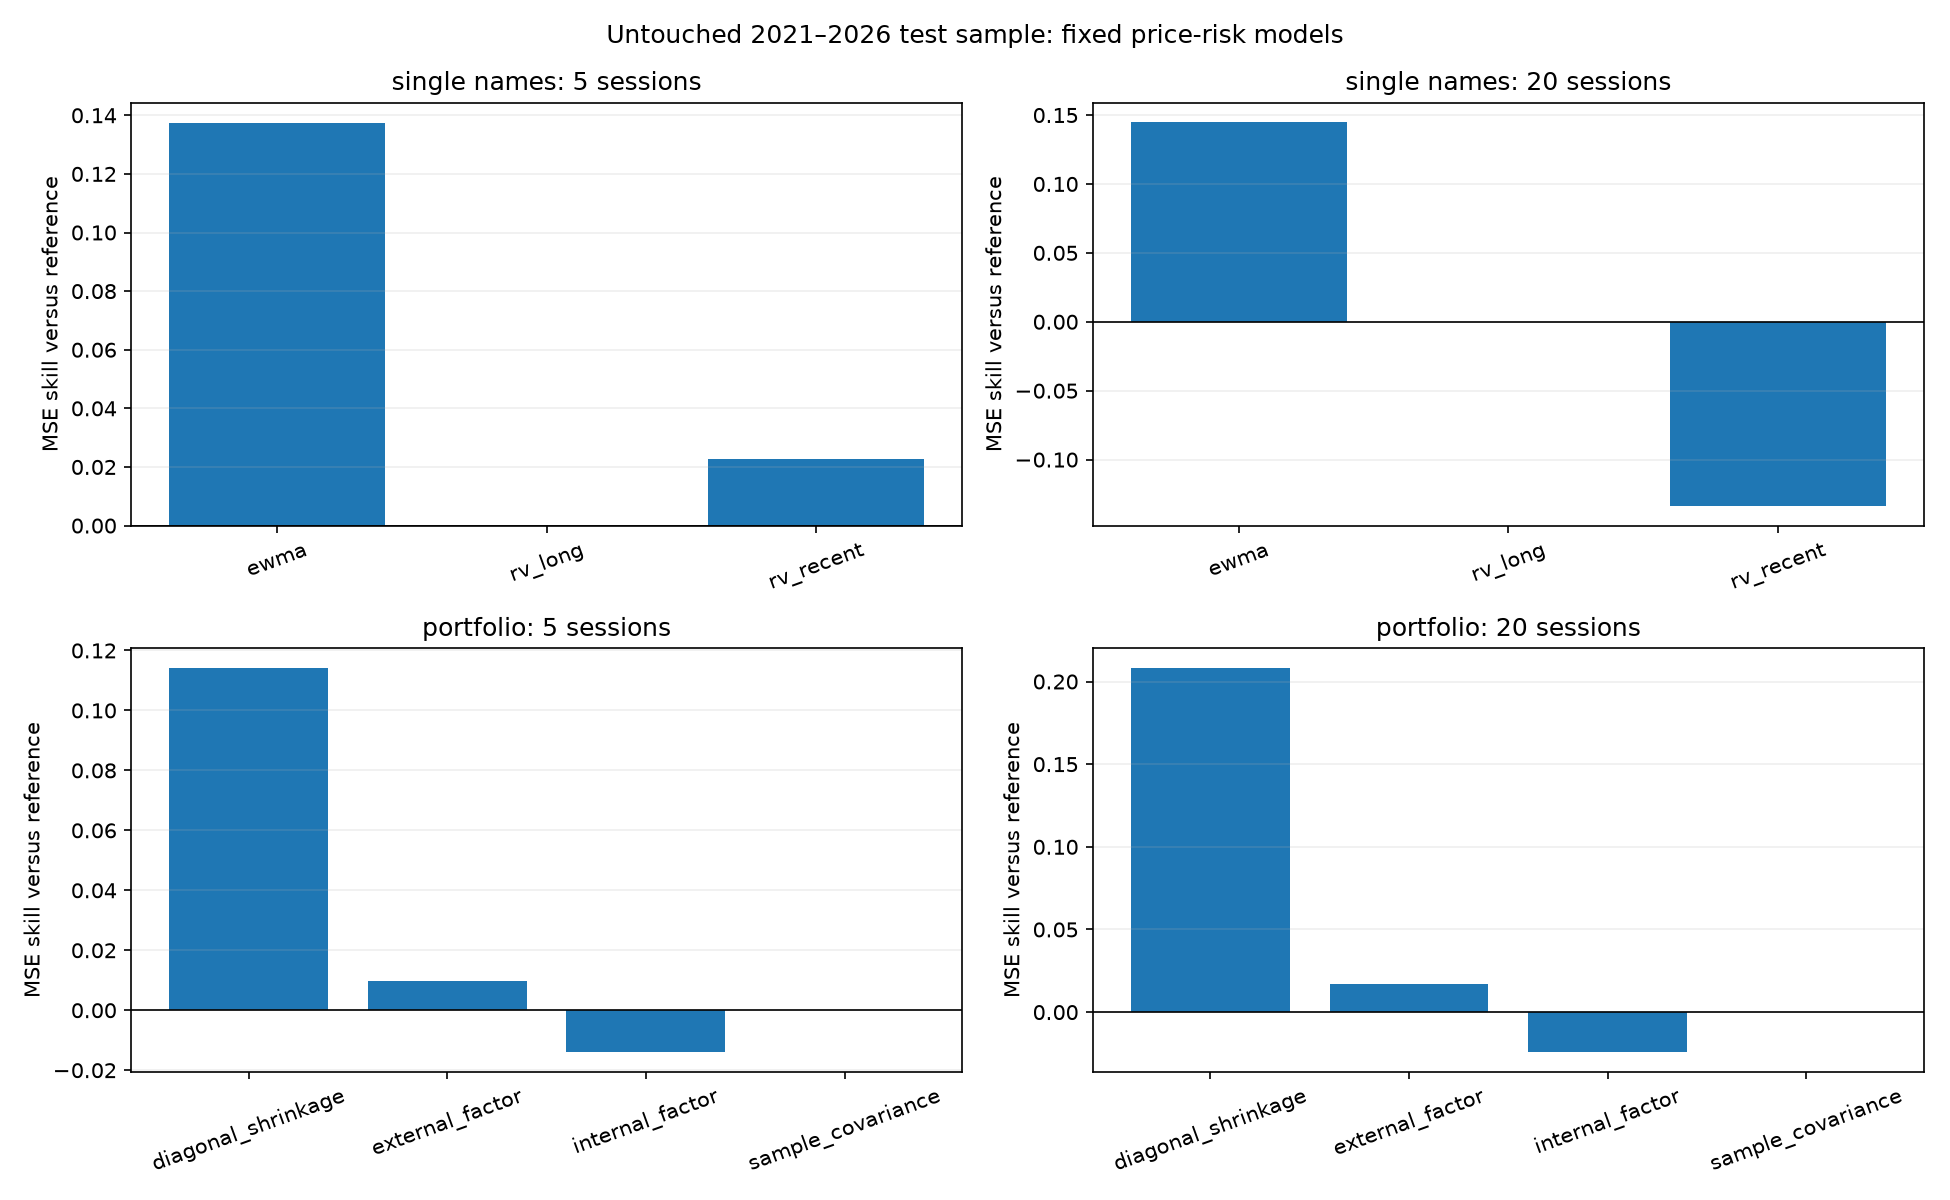

In [3]:
scores = pd.read_csv(output / "pooled_scores.csv")
test_scores = scores.loc[scores["split"].eq("test")]
display(test_scores[[
    "panel", "horizon", "model", "n_dates", "mean_qlike", "mean_mse",
    "mse_skill_vs_baseline", "qlike_difference_vs_baseline"
]])
display(Image(filename=str(output / "test_mse_skill.png")))

## Inspect dependence-aware uncertainty

Negative QLIKE differences favor the alternative model. Each interval is a circular moving-block bootstrap over date-level mean loss differences. It preserves contemporaneous company dependence and does not assume every non-overlapping forecast error is independent across time.

The default test has 293 five-session origins and 73 twenty-session origins. Pointwise intervals crossing zero are reported as inconclusive under this scoring comparison.

,panel,horizon,model,baseline,estimate,lower,upper,n_dates,block_length
0,portfolio,5,diagonal_shrinkage,sample_covariance,0.007612,-0.035452,0.059614,293,13
1,portfolio,5,external_factor,sample_covariance,0.004475,-0.013790,0.026518,293,13
2,portfolio,5,internal_factor,sample_covariance,0.000095,-0.010225,0.008224,293,13
6,portfolio,20,diagonal_shrinkage,sample_covariance,0.008240,-0.040265,0.067481,73,4
7,portfolio,20,external_factor,sample_covariance,0.004016,-0.014206,0.029250,73,4
8,portfolio,20,internal_factor,sample_covariance,-0.000156,-0.012626,0.008489,73,4
24,single_names,5,ewma,rv_long,-0.006059,-0.067403,0.050181,293,13
25,single_names,5,rv_recent,rv_long,0.078475,-0.010481,0.178592,293,13
28,single_names,20,ewma,rv_long,0.023451,-0.072528,0.145585,73,4
29,single_names,20,rv_recent,rv_long,0.145591,-0.021914,0.378847,73,4


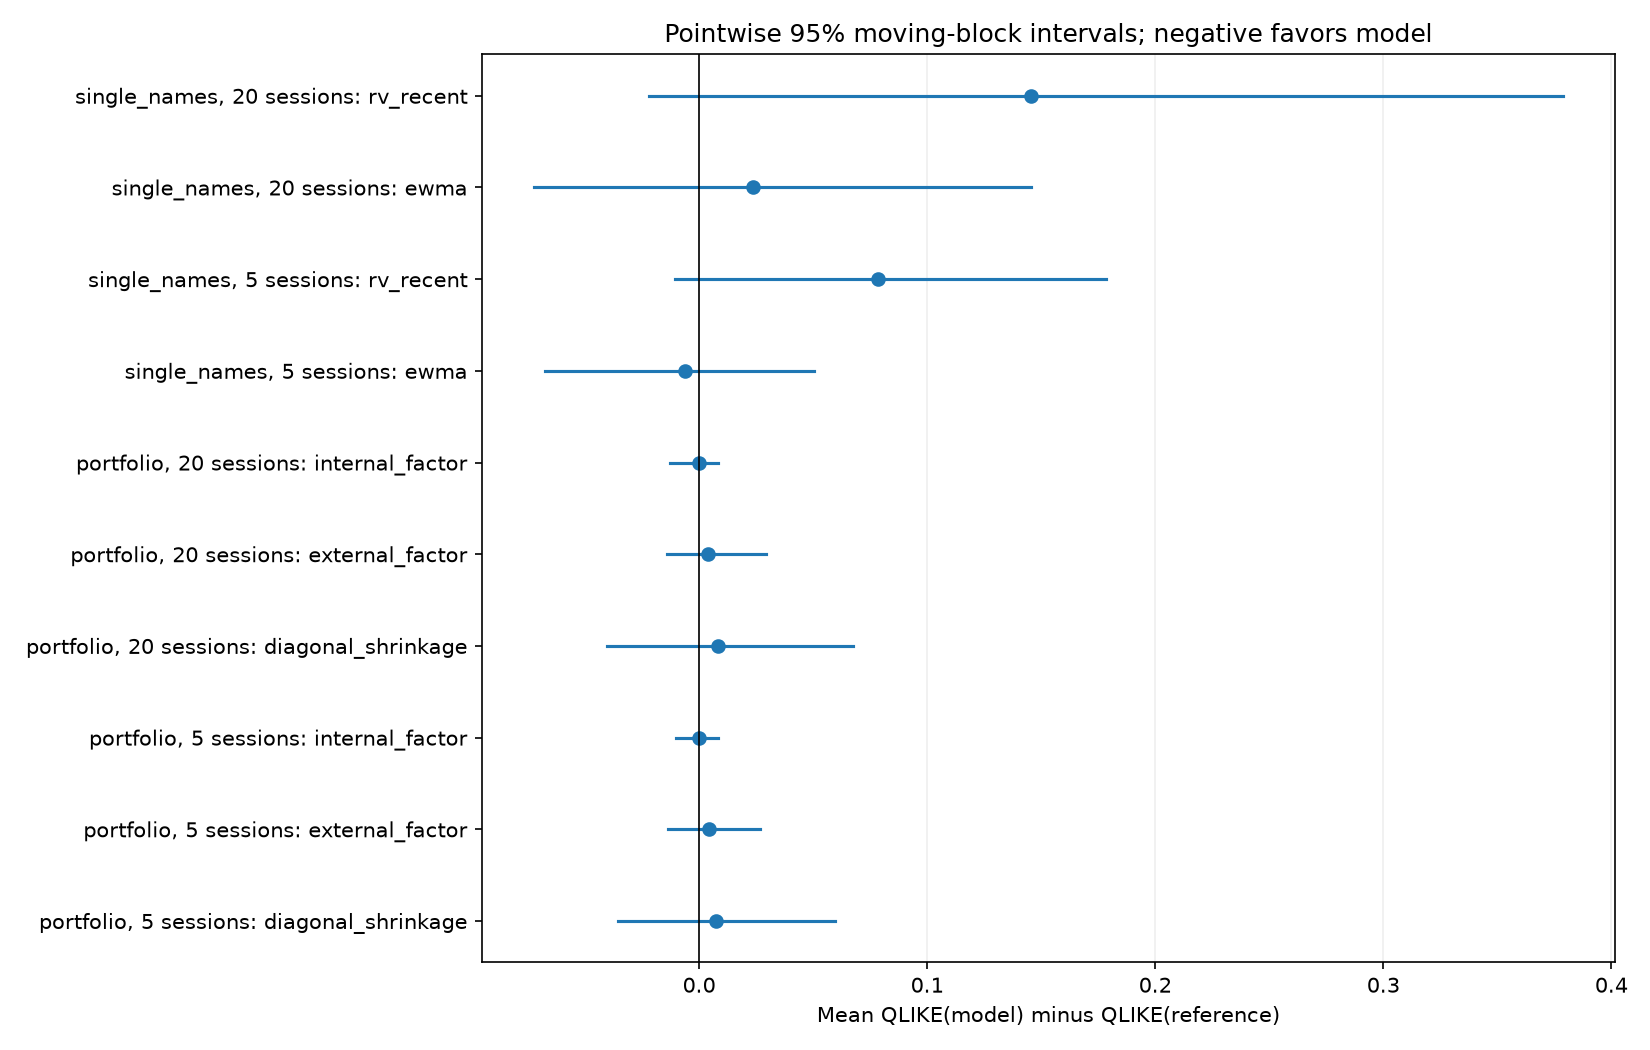

In [4]:
intervals = pd.read_csv(output / "paired_loss_differences.csv")
test_intervals = intervals.loc[intervals["split"].eq("test") & intervals["metric"].eq("qlike")]
display(test_intervals[["panel", "horizon", "model", "baseline", "estimate", "lower", "upper", "n_dates", "block_length"]])
display(Image(filename=str(output / "test_qlike_intervals.png")))

## Interpretation and next research gate

The implementation establishes past-only price forecasts, stable dated covariance estimates and chronological empirical comparisons for the available ten-name sample. Consult the generated report for actual outcomes, including negative and inconclusive comparisons.

The equal-weight return basket is a risk benchmark, not a traded stock/derivative NAV. Stock histories exclude dividend cash flows. Funding/macro features need release-aware observations, and their incremental forecast value must be tested before claiming improvement. Forecast-to-hedge outcomes, equity overlays and survivorship-aware breadth are separate gates.